# CSE475 Task 2 (part 2): proposed temporal-graph GCN
**Group 02** — Md. Anwar Nabil Araf (2023-2-60-242), Jagannath Banik (2023-2-60-144), Md Naimul Islam Rafi (2023-2-60-209), Mst Mahabuba Akter Eka (2023-1-60-134). Submitted to Associate Professor Dr. Raihan ul Islam.

Same fixed segment-level split as the baselines (300/100/100). Same limitation: no patient IDs, so results are segment-level.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
# Works locally and in Colab: find the repo root, or clone it.
here = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'outputs/task1/split_manifest.csv').exists()), None)
if here is None:
    import subprocess; subprocess.run(['git', 'clone', '-q', 'https://github.com/nabilaraf41/Group02_Bonn_CSE475.git'], check=True)
    here = Path('Group02_Bonn_CSE475').resolve()
ROOT = here
sys.path.insert(0, str(ROOT/'code/task2'))
import task2 as t2
OUT = ROOT/'outputs/task2'; OUT.mkdir(parents=True, exist_ok=True)
X, y, split, paths, fs, features = t2.load(ROOT)
print('Signals:', X.shape, '| fs =', fs, 'Hz')
print(pd.crosstab(pd.Series(split, name='split'), pd.Series(np.array(t2.CLASSES)[y], name='class')))
baselines = pd.read_csv(OUT/'baseline_results.csv')

Signals: (500, 4097) | fs = 173.61 Hz
class        F   N   O   S   Z
split                         
test        20  20  20  20  20
train       60  60  60  60  60
validation  20  20  20  20  20


## (A) Graph construction
| Part | Choice | Why |
|---|---|---|
| Graph | one graph per EEG segment | each segment is one labelled example; graphs never connect different segments, so no test information can leak through edges |
| Nodes | 8 contiguous time windows (513 + 7×512 samples ≈ 2.95 s each) | a single channel has no electrodes, so time windows are the natural "parts" of the signal; same design as R5 (Sharma & Gandhi, 2026) |
| Node features | the same 19 Task 1 descriptors, computed per window | keeps inputs identical to the baselines, so any gain comes from the graph, not new features |
| Temporal edges | window *i* ↔ *i*+1 (7 edges) | seizure activity evolves over time; neighbours share context |
| Similarity edges | each window ↔ its *k* most similar windows (Euclidean on standardised features), *k* picked on validation | links windows that look alike even if far apart in time, e.g. repeated spike bursts |
| Proposed | **union** of temporal + similarity | our research question: does order add to similarity? |
| Scaling | `StandardScaler` fitted on **training nodes only** | prevents leakage |

The graph is built after the split and only from each segment's own signal.

In [2]:
NF = t2.node_features(X, fs, features)
np.save(OUT/'node_features.npy', NF)
print('Node feature tensor:', NF.shape, '(segments, nodes, features)')
k = t2.choose_k(NF, y, split)
print('k chosen on validation macro-F1:', k)

Node feature tensor: (500, 8, 19) (segments, nodes, features)


k chosen on validation macro-F1: 3


## (B) Architecture
`EEG segment (4,097 samples)` → split into 8 windows → 19 features per window → **graph** (8 nodes, temporal ∪ similarity edges) → **GCN layer Â·H·W (19→64) + BatchNorm + ReLU + Dropout 0.3** → **GCN layer Â·H·W (64→64) + BatchNorm + ReLU + Dropout 0.3** → **readout: mean-pool ‖ max-pool over nodes (128)** → **Linear(128→5)** → class Z/O/N/F/S.

Training: Adam (lr 1e-3, weight decay 5e-4), batch 32, cross-entropy, up to 300 epochs, early stopping on validation macro-F1 (patience 40). 5 seeds (475–479) to show run-to-run spread. Â = D^-1/2 (A+I) D^-1/2 is the normalised adjacency (Kipf & Welling, 2017), written in plain PyTorch because each graph has only 8 nodes.

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 2.4)); ax.axis('off')
boxes = ['Raw segment\n4,097 samples', '8 time windows\n19 features each', 'Graph\ntemporal ∪ k-NN', 'GCN 19→64\nBN·ReLU·Drop', 'GCN 64→64\nBN·ReLU·Drop', 'Readout\nmean ‖ max', 'Linear 128→5\nZ/O/N/F/S']
for i, b in enumerate(boxes):
    ax.text(i*1.7, 0, b, ha='center', va='center', fontsize=9, bbox=dict(boxstyle='round', fc='#e6f0f4', ec='#1f6f8b'))
    if i: ax.annotate('', (i*1.7-0.62, 0), (i*1.7-1.08, 0), arrowprops=dict(arrowstyle='->'))
ax.set_xlim(-0.8, 11); ax.set_ylim(-1, 1); fig.savefig(OUT/'gcn_architecture.png', dpi=150, bbox_inches='tight'); plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5116\2463126774.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.set_xlim(-0.8, 11); ax.set_ylim(-1, 1); fig.savefig(OUT/'gcn_architecture.png', dpi=150, bbox_inches='tight'); plt.show()


## (C) How the model works, in our own words
1. **Cut the signal into 8 time windows.** A 23.6 s Bonn segment becomes 8 windows of about 3 s. Each window is described by the same 19 numbers we studied in Task 1 (amplitude, line length, spectral band shares, entropy…).
2. **Connect the windows.** Each window is joined to the window before and after it (temporal edges), and to the 3 windows most similar to it (similarity edges; k = 3 was picked on the validation set). Each graph has about 18.6 edges.
3. **Message passing (GCN layer).** Each window updates its description by averaging its own features with its neighbours', then applying a learned weight matrix. After two layers, every window "knows" about windows up to two hops away, so a short spike burst in one window can inform the whole segment.
4. **Readout.** Take the mean (overall behaviour) and the max (strongest local event) over the 8 windows and join them.
5. **Classify.** One linear layer maps that 128-number summary to the 5 classes.

**Why each part is there.** Windows give the model a time structure that one global feature vector throws away. Mean + max readout lets it react both to steady patterns (eyes-closed alpha in O) and to brief events (spikes in F/S). BatchNorm and dropout matter because we have only 300 training graphs. The model is small (6,341 parameters) on purpose.

**Why it should beat the baselines.** The baselines see 19 numbers averaged over the whole 23.6 s. If F and N differ in *when* or *how often* activity changes, not in their averages, the per-window graph can see that and the baselines cannot. That is a hypothesis, which the results below test.

In [4]:
rows, probas, infos = [], {}, []
for mode in ['union', 'temporal', 'similarity']:
    for seed in range(475, 480):
        r, p, info, net = t2.train_gcn(NF, y, split, mode, k=k, seed=seed)
        rows.append({**r, 'seed': seed, **info}); probas[(mode, seed)] = p
runs = pd.DataFrame(rows); runs.to_csv(OUT/'gcn_runs.csv', index=False)
cols = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc_ovr_macro', 'pr_auc_macro', 'recall_Z', 'recall_O', 'recall_N', 'recall_F', 'recall_S', 'train_time_s', 'parameters']
summary = runs.groupby('model')[cols].agg(['mean', 'std'])
summary.to_csv(OUT/'gcn_summary.csv'); display(summary.round(4))

accuracy         f1_macro         f1_weighted          \
                     mean     std     mean     std        mean     std   
model                                                                    
GCN (similarity)    0.834  0.0207   0.8303  0.0209      0.8303  0.0209   
GCN (temporal)      0.852  0.0164   0.8499  0.0167      0.8499  0.0167   
GCN (union)         0.836  0.0404   0.8335  0.0415      0.8335  0.0415   

                 roc_auc_ovr_macro         pr_auc_macro          ... recall_N  \
                              mean     std         mean     std  ...     mean   
model                                                            ...            
GCN (similarity)            0.9704  0.0039       0.8863  0.0124  ...     0.74   
GCN (temporal)              0.9726  0.0049       0.8990  0.0163  ...     0.70   
GCN (union)                 0.9724  0.0077       0.8933  0.0289  ...     0.66   

                         recall_F         recall_S      train_time_s          \
                     std     mean     std     mean  std         mean     std   
model                                                                          
GCN (similarity)  0.0962     0.61  0.0224      1.0  0.0      11.7885  5.8196   
GCN (temporal)    0.0354     0.73  0.0274      1.0  0.0      13.0026  3.4466   
GCN (union)       0.0652     0.69  0.1194      1.0  0.0      12.2324  7.5397   

                 parameters       
                       mean  std  
model                             
GCN (similarity)     6341.0  0.0  
GCN (temporal)       6341.0  0.0  
GCN (union)          6341.0  0.0  

[3 rows x 24 columns]

Representative union run: seed 477
              precision    recall  f1-score   support

           Z      0.870     1.000     0.930        20
           O      1.000     0.950     0.974        20
           N      0.824     0.700     0.757        20
           F      0.750     0.750     0.750        20
           S      0.952     1.000     0.976        20

    accuracy                          0.880       100
   macro avg      0.879     0.880     0.877       100
weighted avg      0.879     0.880     0.877       100



,model,f1_macro,accuracy,kind,f1_macro_std
0,Random Forest,0.8595,0.86,baseline,NaN
1,Gradient Boosting,0.8514,0.85,baseline,NaN
1,GCN (temporal),0.8499,NaN,proposed,0.0167
2,GCN (union),0.8335,NaN,proposed,0.0415
0,GCN (similarity),0.8303,NaN,proposed,0.0209
2,XGBoost,0.8174,0.82,baseline,NaN
3,SVM (RBF),0.8090,0.82,baseline,NaN
4,Logistic Regression,0.8057,0.81,baseline,NaN
5,1D-CNN (raw signal),0.7922,0.80,baseline,NaN
6,Decision Tree,0.7767,0.78,baseline,NaN


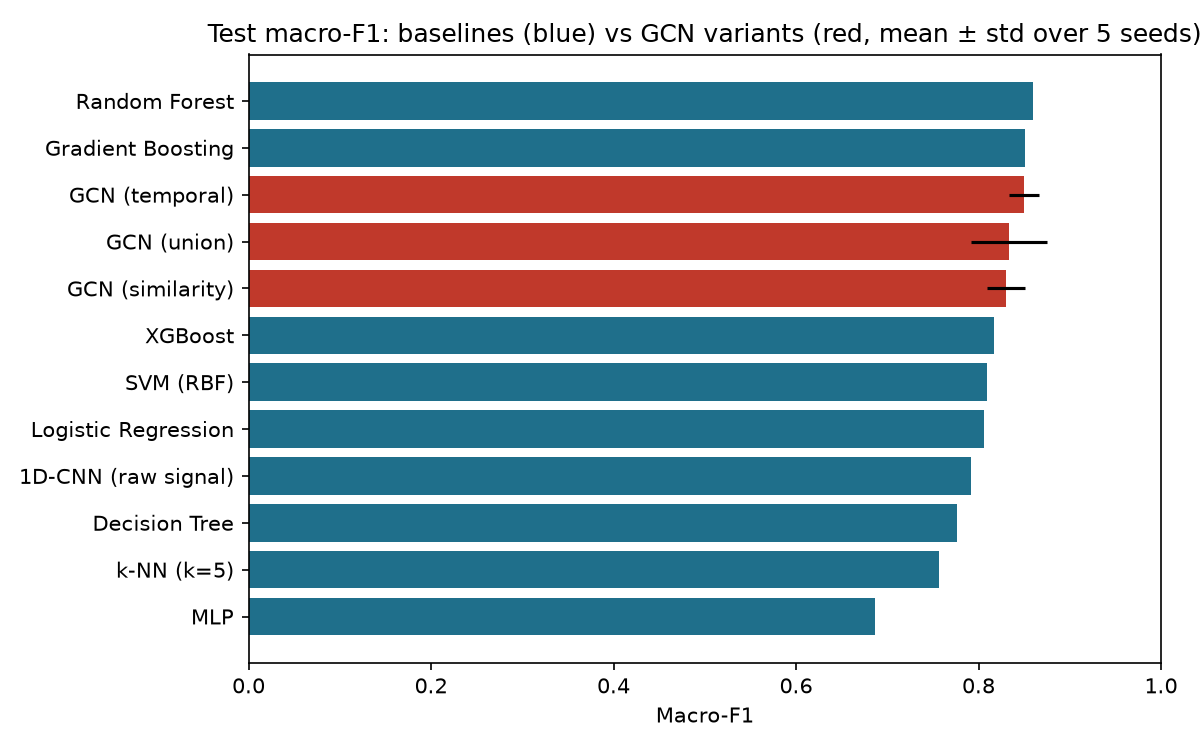

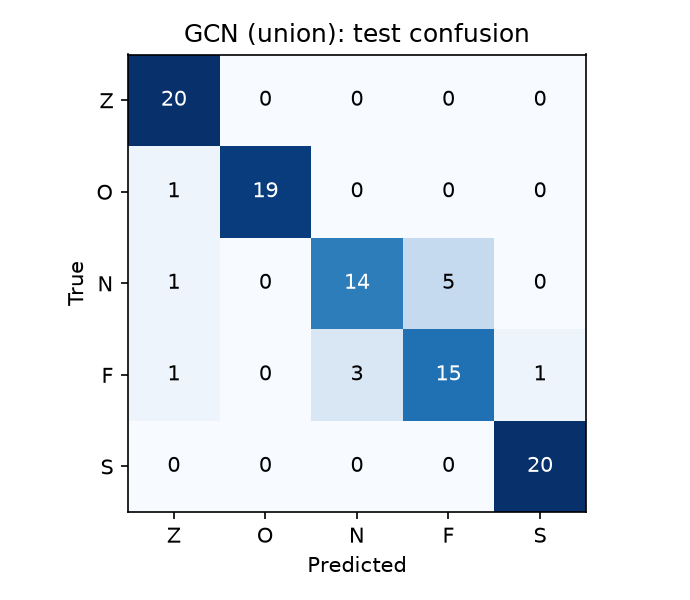

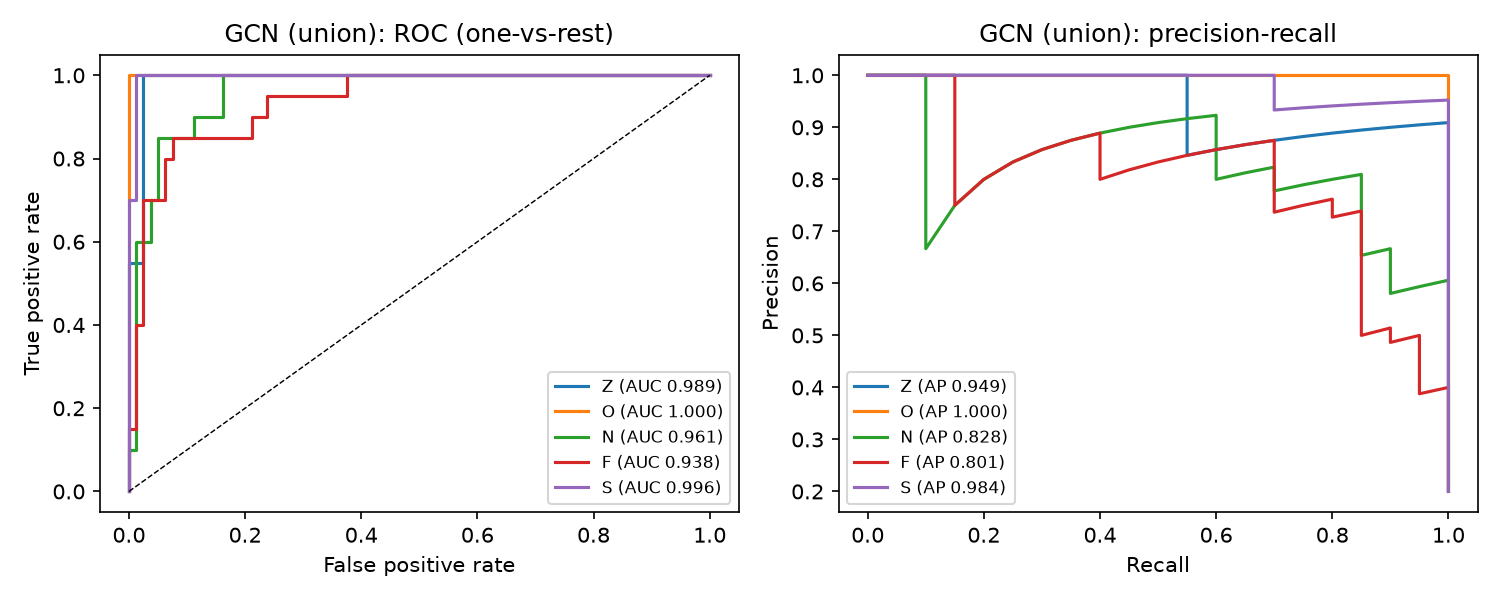

In [5]:
yt = y[split == 'test']
# representative proposed run = the seed with the best VALIDATION macro-F1 (never chosen on test)
u = runs[runs.model == 'GCN (union)']; rep = int(u.loc[u.val_macro_f1.idxmax(), 'seed'])
pu = probas[('union', rep)]
print('Representative union run: seed', rep)
print(t2.classification_report(yt, pu.argmax(1), target_names=t2.CLASSES, digits=3))
t2.plot_confusion(yt, pu.argmax(1), 'GCN (union): test confusion', OUT/'gcn_union_confusion.png')
t2.plot_roc_pr(yt, pu, 'GCN (union)', OUT/'gcn_union_roc_pr.png')
g = runs.groupby('model').f1_macro.agg(['mean', 'std']).reset_index().rename(columns={'mean': 'f1_macro', 'std': 'f1_macro_std'})
comp = pd.concat([baselines[['model', 'f1_macro', 'accuracy']].assign(kind='baseline'), g.assign(kind='proposed')]).sort_values('f1_macro', ascending=False)
comp.to_csv(OUT/'task2_comparison.csv', index=False); display(comp.round(4))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(comp.model, comp.f1_macro, xerr=comp.f1_macro_std.fillna(0), color=['#c0392b' if k == 'proposed' else '#1f6f8b' for k in comp.kind]); ax.invert_yaxis()
ax.set(title='Test macro-F1: baselines (blue) vs GCN variants (red, mean ± std over 5 seeds)', xlabel='Macro-F1', xlim=(0, 1))
fig.tight_layout(); fig.savefig(OUT/'task2_comparison.png', dpi=150)
for f in ['task2_comparison.png', 'gcn_union_confusion.png', 'gcn_union_roc_pr.png']: display(Image(filename=str(OUT/f)))

## First results (honest reading)
| Model | Test macro-F1 |
|---|---|
| Random Forest (best baseline, 1 run) | **0.860** |
| GCN temporal only (5 seeds) | 0.850 ± 0.017 |
| GCN union = proposed (5 seeds) | 0.833 ± 0.041 |
| GCN similarity only (5 seeds) | 0.830 ± 0.021 |
| R5, Sharma & Gandhi 2026, Bonn 5-class (author-reported, different split) | 0.868 ± 0.016 |

- **The GCN does not beat Random Forest yet.** The best GCN variant is about 1 segment behind out of 100, which is within run-to-run noise (std 0.017–0.041).
- **On the research question, adding similarity edges to temporal edges did not help in this first run.** Temporal-only is best and most stable. The union variant has the highest variance (one seed reached 0.877, another 0.776), so similarity edges make training less stable on 300 graphs.
- **Where the GCN helps:** F recall 0.73 (temporal) vs 0.45–0.50 for the linear models and SVM, and 0.80 for Random Forest. **Where it struggles:** N recall 0.66–0.74, often confused with F.
- **ROC-AUC is high (≈0.97)** for all GCN variants, so the ranking is good; mistakes are mostly N↔F threshold errors.
- **For Task 3:** tune depth, hidden size, dropout and learning rate; try GAT/GraphSAGE; compare feature subsets (remove redundant RMS/std); run 5-fold CV and a Wilcoxon test against Random Forest. The graph bonus requires an ablation showing the graph helps; right now it does not clearly help.
- **Limit:** split is segment-level, not patient-level (no patient IDs in Bonn). R5's number uses an undisclosed split, so the comparison is indicative only.